# Inspect spatial maps alongside behavior and video

**Question:** Does a spatial signal line up with the animal's position and
orientation? Check a few frames, play them with behavior and event markers,
and put video and tracking in the same arena coordinates.

**You will need:** A spatial map for each time point, tracking coordinates,
and their timestamps on one clock. Body-part positions, head direction, and
event times can be added when available. We create a small example here;
no recording or video file is needed.

**Estimated time**: 15-20 minutes

**Prerequisites**: [Spatial rate maps](02_spatial_rate_maps.ipynb).

The default run shows figures and an HTML animation. The desktop viewer,
notebook widget, and video export are switched off below. Reading a video
file requires `neurospatial[video]`; desktop and widget viewers use
`neurospatial[animation]`.

In [1]:
import sys
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.transforms import Affine2D as MplAffine2D

from neurospatial import Environment
from neurospatial.animation import (
    BodypartOverlay,
    EventOverlay,
    HeadDirectionOverlay,
    PositionOverlay,
    Skeleton,
    VideoOverlay,
)
from neurospatial.ops.transforms import VideoCalibration, calibrate_from_landmarks

RUN_NAPARI = False
RUN_WIDGET = False
RUN_VIDEO_EXPORT = False
EMBED_HTML = True

_here = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
if not (_here / "_style.py").exists() and (_here / "examples" / "_style.py").exists():
    _here = _here / "examples"
if str(_here) not in sys.path:
    sys.path.insert(0, str(_here))
from _style import apply_style

apply_style(figsize=(10, 5))
artifacts = tempfile.TemporaryDirectory(prefix="neurospatial-visualization-")
output_dir = Path(artifacts.name)

## 1. Prepare maps and tracking on the same clock

Each row of `fields` contains one value per spatial bin. We use 16 maps at
8 Hz, with timestamps from 0 to 1.875 s. Position and body-part coordinates
are `(x, y)` in centimeters. Head direction is in radians: zero points East
and positive angles turn toward North.

The example signal is a Gaussian that follows the simulated animal. Its
values are in arbitrary units: they are neither measured firing rates nor
decoded probabilities. The nose, body, and tail follow the direction of
movement here. In a recording, head or body orientation can differ from
movement direction. The next cell prepares these example inputs.

In [2]:
env = Environment.from_grid_mask(
    np.ones((20, 20), dtype=bool),
    grid_edges=(np.arange(0, 105, 5.0), np.arange(0, 105, 5.0)),
)
env.units = "cm"
env.regions.add("reference", point=np.array([50.0, 50.0]))
n_frames, fps = 16, 8.0
frame_times = np.arange(n_frames) / fps
phase = 2 * np.pi * np.arange(n_frames) / n_frames
trajectory = np.column_stack([50 + 25 * np.cos(phase), 50 + 25 * np.sin(phase)])
heading = phase + np.pi / 2
direction = np.column_stack([np.cos(heading), np.sin(heading)])
pose = {
    "nose": trajectory + 4 * direction,
    "body": trajectory,
    "tail": trajectory - 4 * direction,
}
skeleton = Skeleton(
    name="synthetic_pose",
    nodes=("nose", "body", "tail"),
    edges=(("nose", "body"), ("body", "tail")),
    edge_color="white",
    edge_width=2.0,
)
offsets = env.bin_centers[None, :, :] - trajectory[:, None, :]
fields = np.exp(-np.sum(offsets**2, axis=-1) / (2 * 12.0**2))
view_settings = {"frame_times": frame_times, "cmap": "magma", "vmin": 0, "vmax": 1}
print(
    f"{n_frames} maps, {env.n_bins} spatial bins per map; "
    f"map data use {fields.nbytes / 1e6:.2f} MB"
)

16 maps, 400 spatial bins per map; map data use 0.05 MB


## 2. Inspect a few frames before making a movie

Use the same color limits for every frame. A changing automatic scale can
make a stable signal appear to change amplitude. Here the color range is
fixed at 0-1. The cyan line shows the movement history, and the white linked
points show the tail, body, and nose.

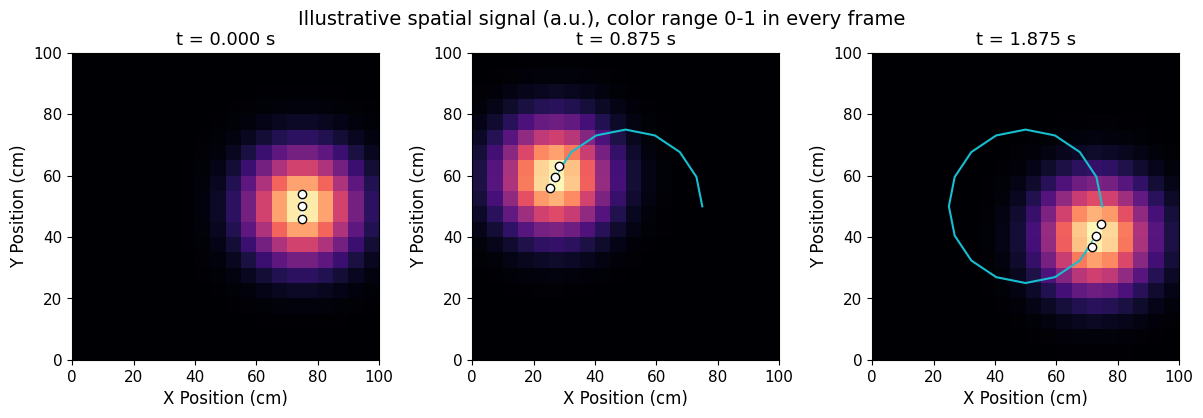

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4), constrained_layout=True)
for ax, index in zip(axes, [0, 7, 15], strict=True):
    env.plot_field(fields[index], ax=ax, vmin=0, vmax=1, colorbar=False, cmap="magma")
    ax.plot(trajectory[: index + 1, 0], trajectory[: index + 1, 1], color="tab:cyan")
    points = np.array([pose[name][index] for name in ("tail", "body", "nose")])
    ax.plot(points[:, 0], points[:, 1], "wo-", lw=2, markeredgecolor="black")
    ax.set_title(f"t = {frame_times[index]:.3f} s")
fig.suptitle("Illustrative spatial signal (a.u.), color range 0-1 in every frame")
plt.show()

The bright area follows the animal because we constructed it that way.
For a measured signal, inspect whether changes reflect the data, missing
observations, or a display choice. Check the positions of the body parts
and the arena axes before interpreting a relationship with neural activity.

## 3. Play the maps with behavior and event markers

The HTML player adds the tracked position and its recent path, linked body
parts, and a yellow head-direction arrow. Green marks show two example
events at the animal's position. Each added element is an `Overlay` object
with its own timestamps. We use the same clock for all of them.

In [4]:
overlays = [
    PositionOverlay(
        trajectory, times=frame_times, color="cyan", size=5, trail_length=5
    ),
    BodypartOverlay(pose, times=frame_times, skeleton=skeleton),
    HeadDirectionOverlay(heading, times=frame_times, length=10.0, color="yellow"),
    EventOverlay(
        event_times=frame_times[[4, 12]],
        event_positions=trajectory[[4, 12]],
        colors="lime",
        size=9,
        decay_frames=4,
    ),
]
html_path = env.animate_fields(
    fields,
    overlays=overlays,
    show_regions=True,
    backend="html",
    save_path=str(output_dir / "spatial_scene.html"),
    embed=EMBED_HTML,
    n_workers=2,
    dpi=60,
    frame_labels=[f"t = {time:.3f} s" for time in frame_times],
    **view_settings,
)
print(f"Animation saved: {html_path} ({html_path.stat().st_size / 1e6:.2f} MB)")
if "get_ipython" in globals() and EMBED_HTML:
    from IPython.display import HTML, display

    display(HTML(filename=str(html_path)))

Encoding frames:   0%|          | 0/16 [00:00<?, ?it/s]

Encoding frames:  38%|███▊      | 6/16 [00:00<00:00, 44.05it/s]

Encoding frames:  88%|████████▊ | 14/16 [00:00<00:00, 58.71it/s]

Encoding frames: 100%|██████████| 16/16 [00:00<00:00, 56.97it/s]

Animation saved: /var/folders/5c/vh9h5cyd3p71_g3cw0zjnc_m0000gn/T/neurospatial-visualization-aij9wqe2/spatial_scene.html (0.24 MB)


Use the player to check that the path, body parts, and head-direction arrow
move together. Event markers should appear at the expected times and places.
These checks can reveal a clock offset or swapped coordinates in a recording.

`EMBED_HTML=True` keeps all frames inside one HTML file. With False, share
the HTML file together with its separate PNG-frame directory. Both choices
support position, body parts, head direction, events, and regions. HTML does
not display video or additional time-series panels; requesting those produces
a warning. For long recordings, select a short period and select its maps,
timestamps, and tracking together before export.

## 4. Put video and tracking in the same arena coordinates

Video uses `(column, row)` pixels with row increasing downward. Corresponding
arena landmarks use `(x, y)` centimeters with y increasing upward. Pick
landmarks visible in both coordinate systems, such as the arena corners.
The fitted transform includes the change in vertical direction: pass the
original pixel coordinates without flipping them first. Landmark coordinates
also locate the arena origin; a scale bar alone only establishes scale.

We know the exact correspondence for this simulated camera. Fit the mapping,
check the landmark positions, then use it to place the video beneath the map.

In [5]:
width, height = 160, 120
landmarks_px = np.array([[20, 10], [120, 10], [120, 110], [20, 110]], dtype=float)
landmarks_cm = np.array([[0, 100], [100, 100], [100, 0], [0, 0]], dtype=float)
transform = calibrate_from_landmarks(
    landmarks_px, landmarks_cm, frame_size_px=(width, height), kind="similarity"
)
calibration = VideoCalibration(transform, frame_size_px=(width, height))
np.testing.assert_allclose(transform(landmarks_px), landmarks_cm, atol=1e-10)
np.testing.assert_allclose(
    transform(np.array([[70.0, 60.0]])), [[50.0, 50.0]], atol=1e-10
)

The next cell makes a short video with an orange marker at the simulated
animal's position. It only prepares example images.

In [6]:
pixels = transform.inverse()(trajectory)
rows, columns = np.mgrid[:height, :width]
video_frames = np.full((n_frames, height, width, 3), 35, dtype=np.uint8)
video_frames[:, 10:111, 20:121] = 75
for index, (column, row) in enumerate(pixels):
    marker = (columns - column) ** 2 + (rows - row) ** 2 <= 3**2
    video_frames[index, marker] = [255, 180, 0]
print(f"Example video: {n_frames} frames, {video_frames.nbytes / 1e6:.2f} MB")

Example video: 16 frames, 0.92 MB


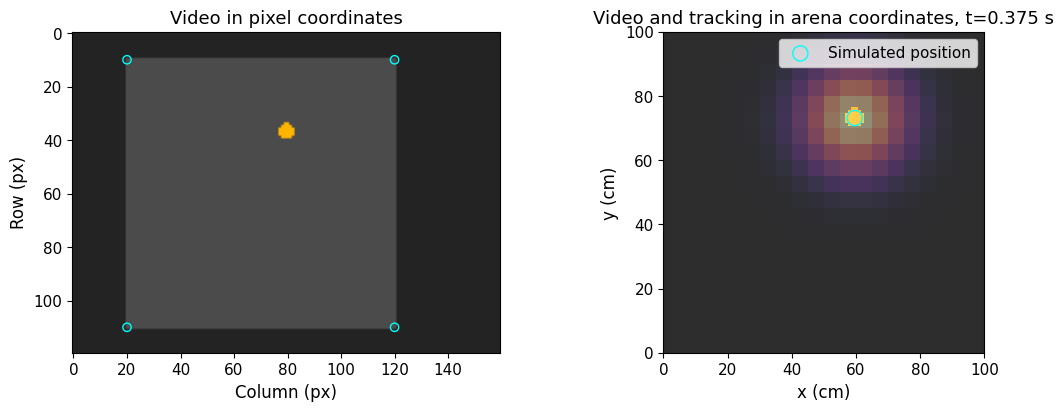

In [7]:
index = 3
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
axes[0].imshow(video_frames[index])
axes[0].scatter(
    landmarks_px[:, 0], landmarks_px[:, 1], facecolors="none", edgecolors="cyan"
)
axes[0].set(xlabel="Column (px)", ylabel="Row (px)", title="Video in pixel coordinates")
# Pixel centers are integer (column, row) coordinates. Apply the complete
# affine mapping to those centers, including Y reflection and any rotation.
axes[1].imshow(
    video_frames[index],
    origin="upper",
    extent=[-0.5, width - 0.5, height - 0.5, -0.5],
    transform=MplAffine2D(transform.A) + axes[1].transData,
)
env.plot_field(
    fields[index], ax=axes[1], alpha=0.4, colorbar=False, vmin=0, vmax=1, cmap="magma"
)
axes[1].scatter(
    *trajectory[index],
    facecolors="none",
    edgecolors="cyan",
    s=120,
    label="Simulated position",
)
axes[1].set(
    xlabel="x (cm)",
    ylabel="y (cm)",
    title=f"Video and tracking in arena coordinates, t={frame_times[index]:.3f} s",
)
axes[1].set_aspect("equal")
axes[1].legend()
plt.show()

The cyan circle should surround the orange video marker after mapping to
arena coordinates. This checks the alignment at a point away from the fitted
corners. A real camera also needs checks at landmarks excluded from the fit;
small errors at fitted landmarks alone do not establish accuracy elsewhere.
Perspective and lens distortion may require a different camera model.

## 5. Optional: open another viewer or save an MP4

To use this cell, change the relevant flag near the imports and rerun it.
Napari needs a working desktop and the animation extra. The widget needs
Jupyter and ipywidgets. MP4 export needs an `ffmpeg` executable. These options
stay off in the default run.

`VideoOverlay` accepts an image array or reads frames from a video file as
needed. Give it video timestamps on the same clock as `frame_times`. Use
transparency to see both video and map when they occupy the same part of the
figure. We select each viewer with its explicit `backend` name below.

In [8]:
video_overlay = VideoOverlay(
    source=video_frames,
    times=frame_times,
    calibration=calibration,
    alpha=0.45,
    z_order="above",
)
if RUN_NAPARI:
    import napari

    viewer = env.animate_fields(
        fields,
        overlays=[*overlays, video_overlay],
        backend="napari",
        **view_settings,
    )
    if "get_ipython" not in globals():
        napari.run()

if RUN_WIDGET:
    env.animate_fields(fields, overlays=overlays, backend="widget", **view_settings)

if RUN_VIDEO_EXPORT:
    from neurospatial.animation.backends.video_backend import check_ffmpeg_available

    if not check_ffmpeg_available():
        raise RuntimeError(
            "Install the ffmpeg executable before enabling RUN_VIDEO_EXPORT."
        )
    env.clear_cache()
    env.animate_fields(
        fields,
        overlays=[*overlays, video_overlay],
        backend="video",
        save_path=str(output_dir / "spatial_scene.mp4"),
        n_workers=2,
        dpi=80,
        **view_settings,
    )

print(
    f"Optional viewers/exports enabled: napari={RUN_NAPARI}, "
    f"widget={RUN_WIDGET}, MP4={RUN_VIDEO_EXPORT}"
)

Optional viewers/exports enabled: napari=False, widget=False, MP4=False


## Use your own recording

Replace `fields` with your time-varying maps, with one column per spatial
bin in `env`. Replace `trajectory`, `heading`, and `pose` with the available
tracking, using the same arena coordinates as the maps. Keep head direction
in radians. Use measured orientation when available; movement direction is
not always the direction the animal is facing.

Synchronize video and tracking clocks before displaying them together. Fit
the video mapping from landmarks measured in your recording and inspect
points that were not used for fitting. Start with a few static frames, then
export a short period using fixed color limits.

The example saves HTML in a temporary folder while the kernel is running.
Set `output_dir` to a folder you want to keep, or copy the HTML file there
before closing the kernel. Save the analysis arrays as well as the movie:
[Analyze an NWB recording](09_nwb_io.ipynb) shows how to save rate maps, and
[Position decoding](06_position_decoding.ipynb) provides spatial probability
maps that can be viewed with behavior.